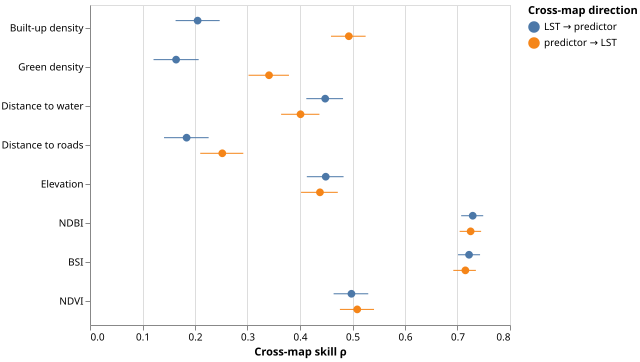

In [1]:
#| label: fig-gccm
import altair as alt, vl_convert as vlc
from IPython.display import display

# Lindner et al. 2026, GCCM at E = 3, tau = 1: cross-map skill (rho) and 95% CI per direction.
gccm = [
    ("Built-up density", 0.493, 0.459, 0.525, 0.205, 0.163, 0.247),
    ("Green density", 0.341, 0.302, 0.379, 0.164, 0.121, 0.207),
    ("Distance to water", 0.401, 0.364, 0.437, 0.448, 0.412, 0.482),
    ("Distance to roads", 0.252, 0.210, 0.292, 0.184, 0.141, 0.226),
    ("Elevation", 0.438, 0.402, 0.472, 0.449, 0.413, 0.483),
    ("NDBI", 0.725, 0.704, 0.745, 0.729, 0.707, 0.749),
    ("BSI", 0.715, 0.692, 0.735, 0.722, 0.701, 0.743),
    ("NDVI", 0.509, 0.476, 0.541, 0.498, 0.464, 0.530),
]
rows = [
    {"predictor": p, "direction": d, "rho": r, "lo": lo, "hi": hi}
    for p, *v in gccm
    for d, r, lo, hi in [("predictor → LST", *v[:3]), ("LST → predictor", *v[3:])]
]

pick = alt.selection_point(fields=["direction"], bind="legend")
base = alt.Chart(alt.Data(values=rows)).encode(
    y=alt.Y("predictor:N", sort=[g[0] for g in gccm], title=None),
    yOffset="direction:N",
    color=alt.Color("direction:N", title="Cross-map direction"),
    opacity=alt.condition(pick, alt.value(1), alt.value(0.15)),
    tooltip=["predictor:N", "direction:N", alt.Tooltip("rho:Q", format=".2f"),
             alt.Tooltip("lo:Q", title="95% CI low", format=".2f"),
             alt.Tooltip("hi:Q", title="95% CI high", format=".2f")],
)
chart = (
    base.mark_rule().encode(x=alt.X("lo:Q", title="Cross-map skill ρ"), x2="hi:Q")
    + base.mark_point(filled=True, size=60).encode(x="rho:Q")
).add_params(pick).properties(width=420, height=320)

display(
    {
        "text/html": chart._repr_mimebundle_(None, None)["text/html"],
        "image/svg+xml": vlc.vegalite_to_svg(chart.to_json()),
    },
    raw=True,
)
